# Halo preference versus stellar mass

Compare the best fit across starts with the fit from the centered initialization.
The scatter plots show raw $\Delta\chi^2=\chi^2_{\rm NFW}-\chi^2_{\rm Burkert}$.
Positive values favor Burkert and negative values favor NFW.

Darker points reach farther inward relative to the disk scale length.
In the inner-coverage views, filled markers have at least three measured radii within two disk scale lengths.
In the bound-contact views, diamonds indicate that at least one of the two plotted fits evaluated a parameter at a bound.
The three-point threshold measures inner sampling coverage.

Run the data-processing and sample-fitting notebooks first. The comparison uses saved attempts.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "models" / "masses.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.plotting import plot_halo_preference_vs_stellar_mass

INPUT_PATH = PROJECT_ROOT / "data/processed/selected_galaxy_rotation_curves.csv"
FIT_DIR = PROJECT_ROOT / "data/processed/halo_fits"
FIGURE_DIR = PROJECT_ROOT / "figures/halo_preference"
summary = pd.read_csv(FIT_DIR / "fit_summary.csv")
metadata = json.loads((FIT_DIR / "fit_config.json").read_text())
if hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest() != metadata["input_sha256"]:
    raise ValueError("Input changed since fitting. Rerun the sample-fitting notebook first.")
galaxies = pd.read_csv(INPUT_PATH.with_name("selected_galaxy_properties.csv"))
attempts = pd.read_csv(FIT_DIR / "fit_attempts.csv")

## Match stellar masses and inner coverage to model fits

In [2]:
if not (np.isfinite(galaxies.stellar_mass_msun) & galaxies.stellar_mass_msun.gt(0)).all():
    raise ValueError("Finite positive stellar masses are required")
comparison = galaxies.assign(log_stellar_mass=np.log10(galaxies.stellar_mass_msun))
models = ["nfw", "burkert"]
if attempts.duplicated(["galaxy", "model", "start"]).any():
    raise ValueError("Duplicate optimizer attempts")
if not attempts.evaluated_at_bound.isin([True, False]).all():
    raise ValueError("Missing or invalid bound-contact flags")
factors = metadata["fit"]["factors"]
start_factors = [(mass, concentration) for mass in factors for concentration in factors]
centered_start = start_factors.index((1, 1)) + 1

valid = attempts.loc[
    attempts.success & attempts.model.isin(models)
    & np.isfinite(attempts[["chi2", "log_m200", "concentration"]]).all(axis=1)
]
best = valid.sort_values(["chi2", "start"]).drop_duplicates(["galaxy", "model"])
centered = valid.loc[valid.start == centered_start]

for label, selected, chi2_columns, prefix in (
    ("Best of all starts", best, models, "best"),
    ("Centered start only", centered, [f"centered_chi2_{model}" for model in models], "centered"),
):
    chi2 = selected.pivot(index="galaxy", columns="model", values="chi2").reindex(columns=models)
    chi2.columns = chi2_columns
    contact = selected.pivot(index="galaxy", columns="model", values="evaluated_at_bound")
    contact = contact.reindex(columns=models).add_prefix(f"{prefix}_evaluated_at_bound_")
    comparison = comparison.join(chi2.join(contact), on="galaxy", validate="one_to_one")
    delta_column = "delta_chi2" if prefix == "best" else "centered_delta_chi2"
    comparison[delta_column] = comparison[chi2_columns[0]] - comparison[chi2_columns[1]]
    excluded = comparison.loc[comparison[delta_column].isna(), "galaxy"]
    print(f"{label}: {len(comparison) - len(excluded)} galaxies plotted")
    if not excluded.empty:
        print("Missing usable fit pair:", ", ".join(excluded))

saved_best = summary.loc[summary.status.eq("success") & summary.model.isin(models)]
actual_best = best.set_index(["galaxy", "model"]).chi2.sort_index()
expected_best = saved_best.set_index(["galaxy", "model"]).chi2.sort_index()
pd.testing.assert_series_equal(actual_best, expected_best)

Best of all starts: 108 galaxies plotted
Centered start only: 108 galaxies plotted


## Best of all starts (All galaxies)

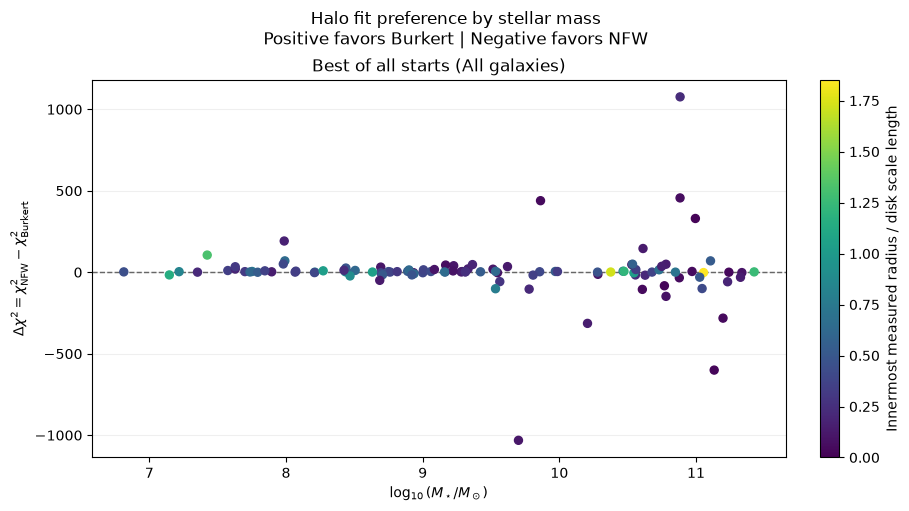

In [3]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=False, encoding="mass")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass.pdf")
plt.show()
plt.close(fig)


## Best of all starts (Inner coverage)

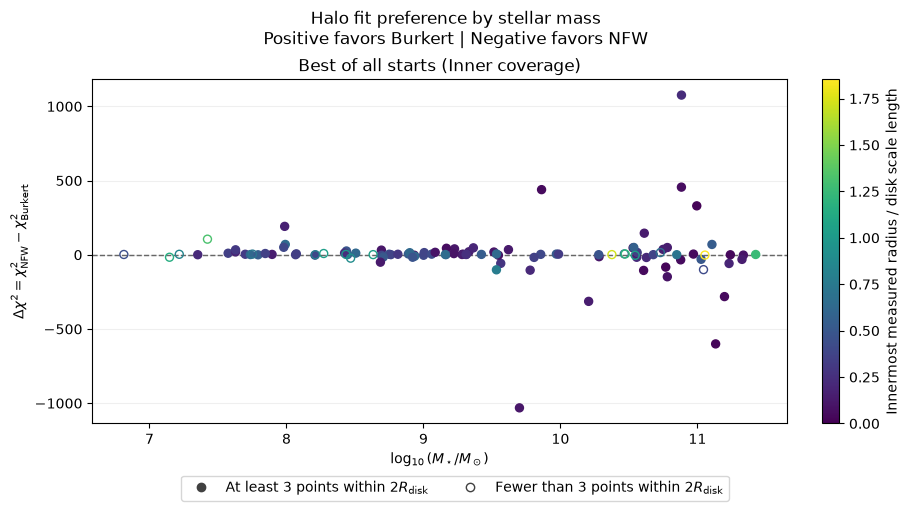

In [4]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=False, encoding="coverage")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_coverage.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_coverage.pdf")
plt.show()
plt.close(fig)


## Centered start only (All galaxies)

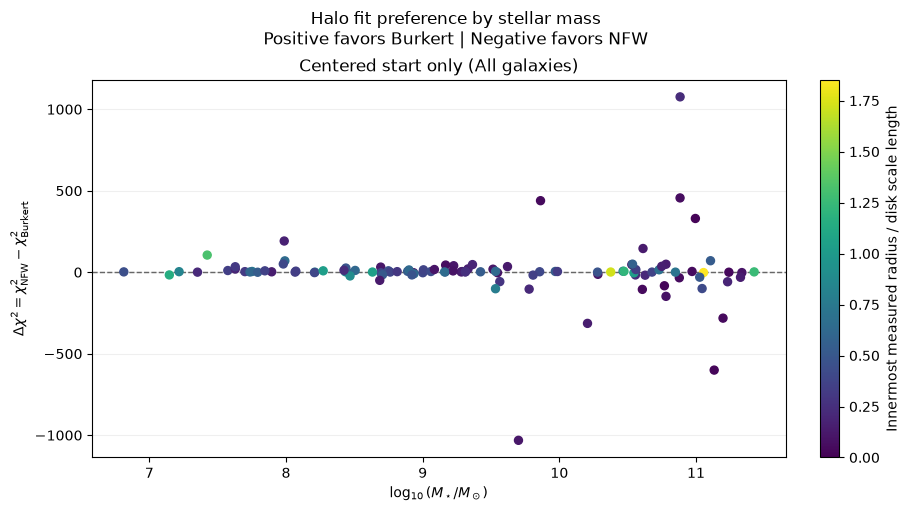

In [5]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=True, encoding="mass")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered.pdf")
plt.show()
plt.close(fig)


## Centered start only (Inner coverage)

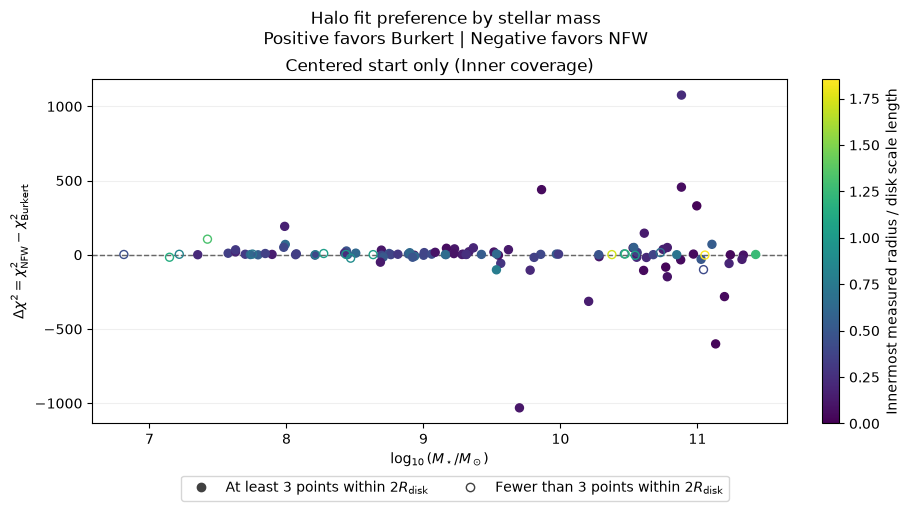

In [6]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plot_halo_preference_vs_stellar_mass(comparison, centered=True, encoding="coverage")
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered_coverage.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_vs_stellar_mass_centered_coverage.pdf")
plt.show()
plt.close(fig)


In [7]:
comparison.to_csv(FIT_DIR / "stellar_mass_halo_preference.csv", index=False)

## Model preference by stellar mass bin

Each bar shows the fractions of galaxies in a 0.5-dex bin that favor Burkert, favor NFW, or have equal chi-squared. The label above each bar gives the number of galaxies with usable fits in that bin.

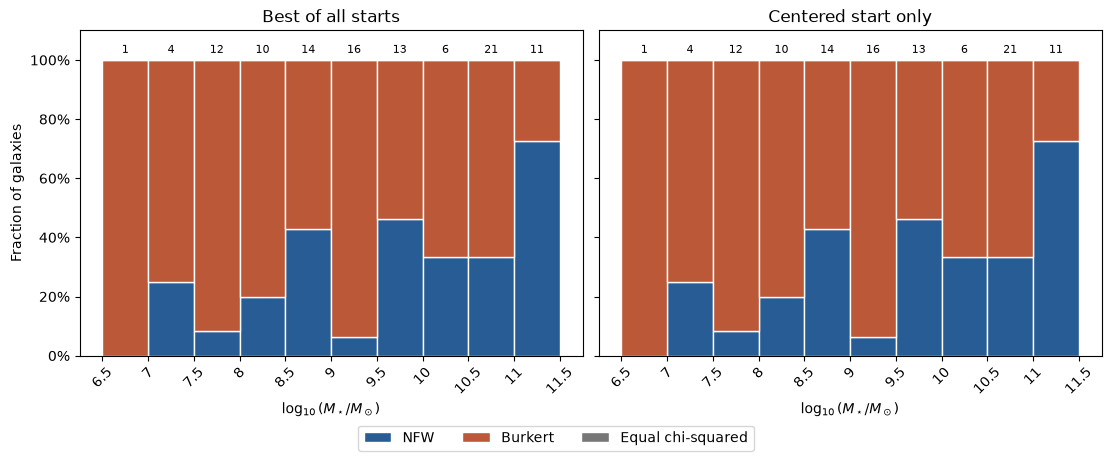

In [8]:
from matplotlib.ticker import PercentFormatter

bin_width = 0.5
log_mass = comparison.log_stellar_mass
first_bin = int(np.floor(log_mass.min() / bin_width))
last_bin = int(np.floor(log_mass.max() / bin_width))
edges = bin_width * np.arange(first_bin, last_bin + 2)

fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(11, 4.5),
                         layout="constrained")
for ax, title, delta_column in zip(
    axes, ("Best of all starts", "Centered start only"),
    ("delta_chi2", "centered_delta_chi2"),
):
    delta = comparison[delta_column]
    bottom = np.zeros(len(edges) - 1)
    categories = (
        (delta.lt(0), "NFW", "#285C94"),
        (delta.gt(0), "Burkert", "#BB5838"),
        (delta.eq(0), "Equal chi-squared", "#777777"),
    )
    totals, _ = np.histogram(log_mass[np.isfinite(delta)], bins=edges)
    occupied = totals > 0
    for mask, label, color in categories:
        counts, _ = np.histogram(log_mass[mask & np.isfinite(delta)], bins=edges)
        fraction = counts[occupied] / totals[occupied]
        ax.bar(edges[:-1][occupied], fraction, bottom=bottom[occupied],
               width=bin_width, align="edge", color=color, edgecolor="white", label=label)
        bottom[occupied] += fraction
    for midpoint, total in zip((edges[:-1] + bin_width / 2)[occupied], totals[occupied]):
        ax.text(midpoint, 1.015, str(total), ha="center", va="bottom", fontsize=8)
    ax.set(title=title, xlabel=r"$\log_{10}(M_\star/M_\odot)$", ylim=(0, 1.10))
    ax.set_xticks(edges, rotation=45, labels=[f"{edge:g}" for edge in edges])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set_ylabel("Fraction of galaxies")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=3)
fig.savefig(FIGURE_DIR / "halo_preference_fraction_by_stellar_mass.png", dpi=300)
fig.savefig(FIGURE_DIR / "halo_preference_fraction_by_stellar_mass.pdf")
plt.show()
plt.close(fig)